In [1]:
!pip install pandas numpy matplotlib seaborn


In [2]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
BASE_DIR = Path("..")

DATA_DIR = BASE_DIR / "data"
SQL_DIR = BASE_DIR / "sql"
VISUALS_DIR = BASE_DIR / "visuals"

DATA_DIR.mkdir(exist_ok=True)
SQL_DIR.mkdir(exist_ok=True)
VISUALS_DIR.mkdir(exist_ok=True)

print("Project folders ready!")

Project folders ready!


In [4]:
np.random.seed(42)

n = 3000

products = [
    "Laptop",
    "Smartphone",
    "Monitor",
    "Keyboard",
    "Mouse",
    "Printer",
    "Tablet",
    "Headphones",
    "Office Chair",
    "Desk"
]

categories = {
    "Laptop": "Technology",
    "Smartphone": "Technology",
    "Monitor": "Technology",
    "Keyboard": "Technology",
    "Mouse": "Technology",
    "Printer": "Office Supplies",
    "Tablet": "Technology",
    "Headphones": "Technology",
    "Office Chair": "Furniture",
    "Desk": "Furniture"
}

regions = [
    "North",
    "South",
    "East",
    "West",
    "Central"
]

segments = [
    "Consumer",
    "Corporate",
    "Home Office"
]

customers = [
    f"CUST{1000+i}"
    for i in range(500)
]

dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-31",
    periods=n
)

product = np.random.choice(
    products,
    n
)

price_map = {
    "Laptop": 65000,
    "Smartphone": 30000,
    "Monitor": 15000,
    "Keyboard": 2000,
    "Mouse": 1000,
    "Printer": 12000,
    "Tablet": 25000,
    "Headphones": 3000,
    "Office Chair": 9000,
    "Desk": 12000
}

quantity = np.random.randint(
    1,
    6,
    n
)

unit_price = np.array([
    price_map[p] * np.random.uniform(0.85, 1.15)
    for p in product
])

discount = np.random.uniform(
    0,
    0.25,
    n
)

sales = (
    quantity *
    unit_price *
    (1 - discount)
)

profit_margin = np.random.uniform(
    0.08,
    0.30,
    n
)

profit = sales * profit_margin

df = pd.DataFrame({

    "Order_ID": [
        f"ORD{10000+i}"
        for i in range(n)
    ],

    "Order_Date": dates,

    "Customer_ID": np.random.choice(
        customers,
        n
    ),

    "Product": product,

    "Category": [
        categories[p]
        for p in product
    ],

    "Region": np.random.choice(
        regions,
        n
    ),

    "Segment": np.random.choice(
        segments,
        n
    ),

    "Quantity": quantity,

    "Unit_Price": unit_price.round(2),

    "Discount": discount.round(2),

    "Sales": sales.round(2),

    "Profit": profit.round(2)
})

df.head()

,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Segment,Quantity,Unit_Price,Discount,Sales,Profit
0,ORD10000,2025-01-01 00:00:00.000000000,CUST1235,Tablet,Technology,North,Corporate,1,28400.52,0.05,26843.32,4149.06
1,ORD10001,2025-01-01 02:54:46.695565188,CUST1152,Keyboard,Technology,West,Consumer,4,1736.14,0.11,6199.94,1613.56
2,ORD10002,2025-01-01 05:49:33.391130376,CUST1467,Headphones,Technology,North,Consumer,5,2817.89,0.16,11791.92,1282.41
3,ORD10003,2025-01-01 08:44:20.086695565,CUST1056,Mouse,Technology,South,Home Office,3,939.42,0.18,2305.95,272.43
4,ORD10004,2025-01-01 11:39:06.782260753,CUST1321,Tablet,Technology,South,Consumer,2,23653.01,0.00,47297.54,7330.78


In [5]:
csv_path = DATA_DIR / "superstore_sales.csv"

df.to_csv(
    csv_path,
    index=False
)

print("Dataset saved:", csv_path)

Dataset saved: ..\data\superstore_sales.csv


In [6]:
db_path = DATA_DIR / "superstore.db"

connection = sqlite3.connect(
    db_path
)

df.to_sql(
    "sales",
    connection,
    if_exists="replace",
    index=False
)

print("SQLite database created successfully!")

SQLite database created successfully!


In [7]:
query = """
SELECT *
FROM sales
LIMIT 10;
"""

result = pd.read_sql_query(
    query,
    connection
)

result

,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Segment,Quantity,Unit_Price,Discount,Sales,Profit
0,ORD10000,2025-01-01 00:00:00,CUST1235,Tablet,Technology,North,Corporate,1,28400.52,0.05,26843.32,4149.06
1,ORD10001,2025-01-01 02:54:46.695565,CUST1152,Keyboard,Technology,West,Consumer,4,1736.14,0.11,6199.94,1613.56
2,ORD10002,2025-01-01 05:49:33.391130,CUST1467,Headphones,Technology,North,Consumer,5,2817.89,0.16,11791.92,1282.41
3,ORD10003,2025-01-01 08:44:20.086695,CUST1056,Mouse,Technology,South,Home Office,3,939.42,0.18,2305.95,272.43
4,ORD10004,2025-01-01 11:39:06.782260,CUST1321,Tablet,Technology,South,Consumer,2,23653.01,0.00,47297.54,7330.78
5,ORD10005,2025-01-01 14:33:53.477825,CUST1374,Desk,Furniture,North,Consumer,4,10791.43,0.23,33055.74,5615.09
6,ORD10006,2025-01-01 17:28:40.173391,CUST1111,Monitor,Technology,North,Consumer,3,16274.23,0.04,46814.54,7336.52
7,ORD10007,2025-01-01 20:23:26.868956,CUST1014,Tablet,Technology,Central,Home Office,5,22168.73,0.06,104370.94,25884.24
8,ORD10008,2025-01-01 23:18:13.564521,CUST1411,Headphones,Technology,North,Consumer,1,3121.42,0.07,2915.81,295.46
9,ORD10009,2025-01-02 02:13:00.260086,CUST1268,Mouse,Technology,North,Home Office,5,887.15,0.01,4393.83,691.01


In [8]:
query = """
SELECT
    SUM(Sales) AS Total_Sales
FROM sales;
"""

pd.read_sql_query(
    query,
    connection
)

,Total_Sales
0,1.388560e+08


In [9]:
query = """
SELECT
    SUM(Profit) AS Total_Profit
FROM sales;
"""

pd.read_sql_query(
    query,
    connection
)

,Total_Profit
0,26351404.45


In [10]:
query = """
SELECT
    COUNT(DISTINCT Order_ID) AS Total_Orders
FROM sales;
"""

pd.read_sql_query(
    query,
    connection
)


,Total_Orders
0,3000


In [11]:
query = """
SELECT
    Category,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

category_sales = pd.read_sql_query(
    query,
    connection
)

category_sales

,Category,Total_Sales
0,Technology,1.134166e+08
1,Furniture,1.665764e+07
2,Office Supplies,8.781780e+06


In [12]:
query = """
SELECT
    Region,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Region
ORDER BY Total_Sales DESC;
"""

region_sales = pd.read_sql_query(
    query,
    connection
)

region_sales

,Region,Total_Sales
0,South,29876504.85
1,North,28889432.32
2,East,27546972.46
3,West,26880890.00
4,Central,25662238.06


In [13]:
query = """
SELECT
    Category,
    SUM(Profit) AS Total_Profit
FROM sales
GROUP BY Category
ORDER BY Total_Profit DESC;
"""

category_profit = pd.read_sql_query(
    query,
    connection
)

category_profit

,Category,Total_Profit
0,Technology,21530435.62
1,Furniture,3119989.48
2,Office Supplies,1700979.35


In [14]:
query = """
SELECT
    Product,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Product
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(
    query,
    connection
)

top_products

,Product,Total_Sales
0,Laptop,54379326.06
1,Smartphone,22859061.41
2,Tablet,19027706.96
3,Monitor,12294248.10
4,Desk,9376779.99
5,Printer,8781779.50
6,Office Chair,7280858.99
7,Headphones,2560641.77
8,Keyboard,1464446.63
9,Mouse,831188.28


In [15]:
query = """
SELECT
    Customer_ID,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Customer_ID
ORDER BY Total_Sales DESC
LIMIT 10;
"""

top_customers = pd.read_sql_query(
    query,
    connection
)

top_customers

,Customer_ID,Total_Sales
0,CUST1396,938826.00
1,CUST1210,853058.48
2,CUST1165,849175.84
3,CUST1049,824485.32
4,CUST1111,801524.35
5,CUST1076,764850.23
6,CUST1179,732814.47
7,CUST1448,729362.18
8,CUST1102,721940.80
9,CUST1429,709884.15


In [16]:
query = """
SELECT
    AVG(Order_Total) AS Average_Order_Value
FROM (
    SELECT
        Order_ID,
        SUM(Sales) AS Order_Total
    FROM sales
    GROUP BY Order_ID
);
"""

average_order_value = pd.read_sql_query(
    query,
    connection
)

average_order_value

,Average_Order_Value
0,46285.345897


In [17]:
query = """
SELECT
    strftime('%Y-%m', Order_Date) AS Month,
    SUM(Sales) AS Total_Sales
FROM sales
GROUP BY Month
ORDER BY Month;
"""

monthly_sales = pd.read_sql_query(
    query,
    connection
)

monthly_sales

,Month,Total_Sales
0,2025-01,12963153.45
1,2025-02,11298755.16
2,2025-03,13045297.28
3,2025-04,10062479.09
4,2025-05,12326635.32
5,2025-06,12273363.10
6,2025-07,11085952.98
7,2025-08,12683689.96
8,2025-09,11299832.95
9,2025-10,11040904.04


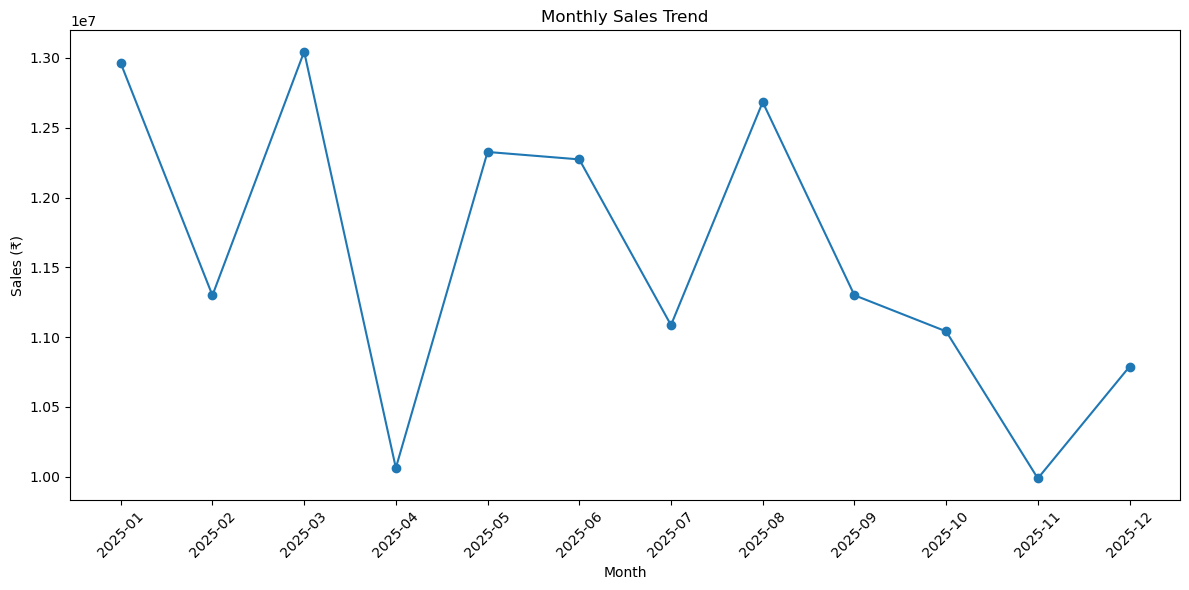

In [18]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title(
    "Monthly Sales Trend"
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "Sales (₹)"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "monthly_sales.png",
    dpi=300
)

plt.show()

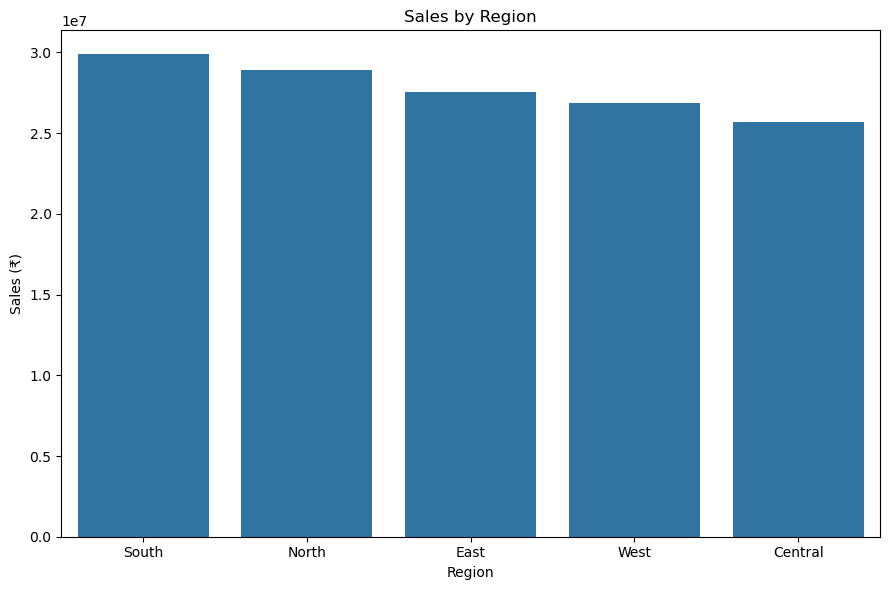

In [19]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Total_Sales"
)

plt.title(
    "Sales by Region"
)

plt.xlabel(
    "Region"
)

plt.ylabel(
    "Sales (₹)"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "sales_by_region.png",
    dpi=300
)

plt.show()

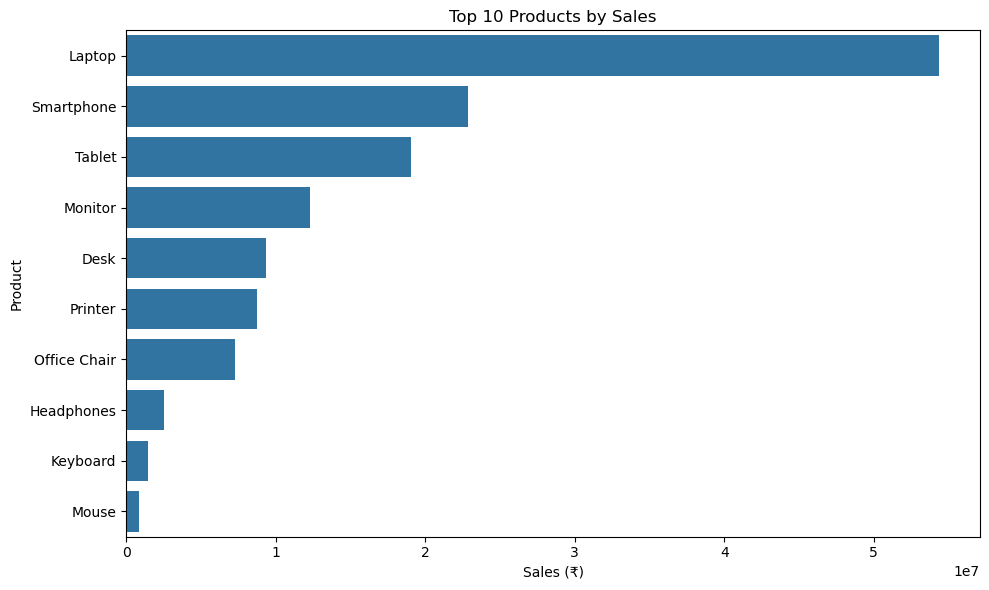

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_products,
    x="Total_Sales",
    y="Product"
)

plt.title(
    "Top 10 Products by Sales"
)

plt.xlabel(
    "Sales (₹)"
)

plt.ylabel(
    "Product"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "top_products.png",
    dpi=300
)

plt.show()

In [21]:
profit_by_region = pd.read_sql_query(
    """
    SELECT
        Region,
        SUM(Profit) AS Total_Profit
    FROM sales
    GROUP BY Region
    ORDER BY Total_Profit DESC;
    """,
    connection
)

profit_by_region

,Region,Total_Profit
0,South,5517360.57
1,North,5444256.01
2,West,5174790.33
3,East,5140846.30
4,Central,5074151.24


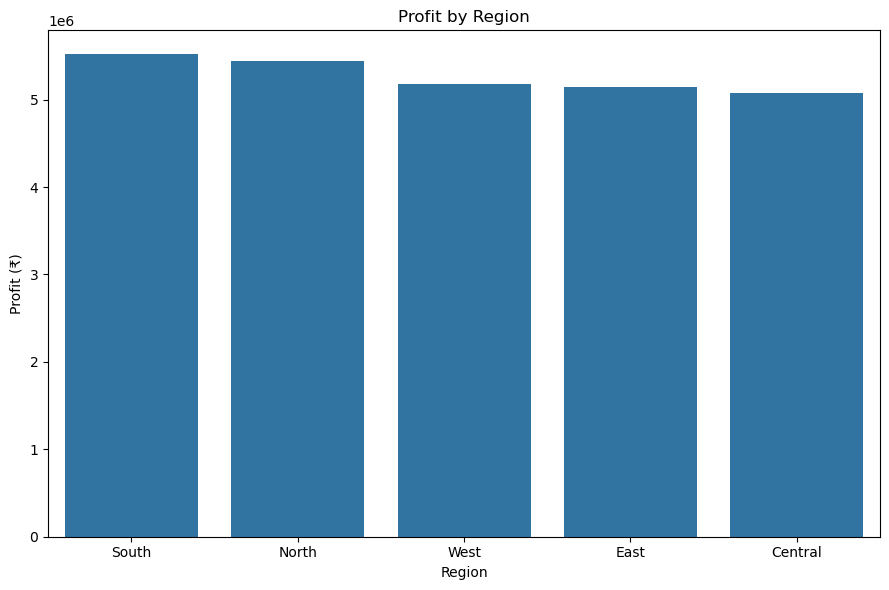

In [22]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=profit_by_region,
    x="Region",
    y="Total_Profit"
)

plt.title(
    "Profit by Region"
)

plt.xlabel(
    "Region"
)

plt.ylabel(
    "Profit (₹)"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "profit_by_region.png",
    dpi=300
)

plt.show()

In [23]:
discount_profit = pd.read_sql_query(
    """
    SELECT
        Discount,
        AVG(Profit) AS Average_Profit
    FROM sales
    GROUP BY Discount
    ORDER BY Discount;
    """,
    connection
)

discount_profit.head()

,Discount,Average_Profit
0,0.00,13490.277324
1,0.01,9631.147500
2,0.02,10508.291442
3,0.03,8026.037840
4,0.04,9208.545000


In [24]:
total_sales = pd.read_sql_query(
    """
    SELECT SUM(Sales) AS value
    FROM sales;
    """,
    connection
)["value"][0]

total_profit = pd.read_sql_query(
    """
    SELECT SUM(Profit) AS value
    FROM sales;
    """,
    connection
)["value"][0]

best_category = category_sales.iloc[0]["Category"]

best_region = region_sales.iloc[0]["Region"]

best_product = top_products.iloc[0]["Product"]

best_profit_region = profit_by_region.iloc[0]["Region"]

print("=" * 60)
print("BUSINESS INSIGHTS")
print("=" * 60)

print(
    f"Total Sales: ₹{total_sales:,.2f}"
)

print(
    f"Total Profit: ₹{total_profit:,.2f}"
)

print(
    f"Best Category: {best_category}"
)

print(
    f"Best Region: {best_region}"
)

print(
    f"Top Product: {best_product}"
)

print(
    f"Most Profitable Region: {best_profit_region}"
)

print("=" * 60)

BUSINESS INSIGHTS
Total Sales: ₹138,856,037.69
Total Profit: ₹26,351,404.45
Best Category: Technology
Best Region: South
Top Product: Laptop
Most Profitable Region: South
